In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Tabla uniforme con paso constante dt = 1.0 min (12 puntos: 0:00 a 11:00 min)
datos = {
    'Etapa': [
        'Carga del café verde',
        'Inicio del secado',
        'Secado intermedio',
        'Secado avanzado',
        'Amarillamiento',
        'Transición a Maillard',
        'Inicio de Maillard',
        'Maillard avanzado',
        'Desarrollo de color',
        'Primer crack',
        'Desarrollo del tueste',
        'Descarga'
    ],
    'Tiempo': [
        '0:00 min',
        '1:00 min',
        '2:00 min',
        '3:00 min',
        '4:00 min',
        '5:00 min',
        '6:00 min',
        '7:00 min',
        '8:00 min',
        '9:00 min',
        '10:00 min',
        '11:00 min'
    ],
    'Temperatura aproximada': [
        '100 °C',
        '110 °C',
        '126 °C',
        '145 °C',
        '155 °C',
        '165 °C',
        '175 °C',
        '182 °C',
        '189 °C',
        '196 °C',
        '202 °C',
        '205 °C'
    ],
    # Columnas numéricas con paso uniforme dt = 1.0 min para Diferencias Finitas
    'tiempo_min': [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0, 11.0],
    'temperatura_C': [100.0, 110.0, 126.0, 145.0, 155.0, 165.0, 175.0, 182.0, 189.0, 196.0, 202.0, 205.0]
}

df_tueste = pd.DataFrame(datos)

# 2. Exportar el dataset limpio a la carpeta 'datos/'
ruta_csv = '../datos/datos_tueste_cafe.csv'
df_tueste.to_csv(ruta_csv, index=False, encoding='utf-8-sig')

print(f"Dataset guardado en: {ruta_csv} | Paso uniforme dt = 1.0 min | Total puntos: {len(df_tueste)}")

# 3. Mostrar la tabla visual igual a la imagen de referencia
tabla_visual = df_tueste[['Etapa', 'Tiempo', 'Temperatura aproximada']].style.hide(axis='index').set_properties(
    subset=['Etapa'], **{'text-align': 'left', 'padding-right': '40px'}
).set_properties(
    subset=['Tiempo'], **{'text-align': 'center', 'padding': '8px 30px'}
).set_properties(
    subset=['Temperatura aproximada'], **{'text-align': 'right', 'padding-left': '40px'}
)

tabla_visual


Dataset guardado en: ../datos/datos_tueste_cafe.csv | Paso uniforme dt = 1.0 min | Total puntos: 12


Etapa,Tiempo,Temperatura aproximada
Carga del café verde,0:00 min,100 °C
Inicio del secado,1:00 min,110 °C
Secado intermedio,2:00 min,126 °C
Secado avanzado,3:00 min,145 °C
Amarillamiento,4:00 min,155 °C
Transición a Maillard,5:00 min,165 °C
Inicio de Maillard,6:00 min,175 °C
Maillard avanzado,7:00 min,182 °C
Desarrollo de color,8:00 min,189 °C
Primer crack,9:00 min,196 °C


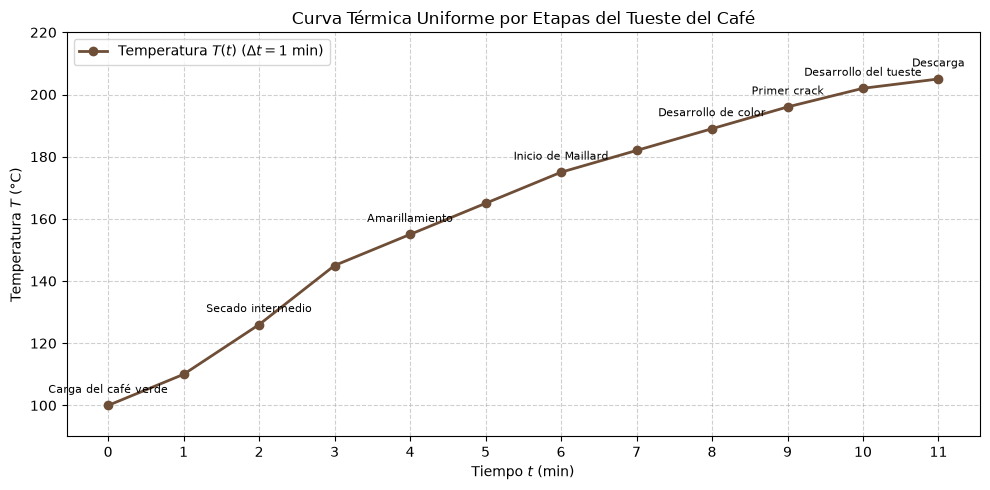

In [5]:
plt.figure(figsize=(10, 5))
plt.plot(df_tueste['tiempo_min'], df_tueste['temperatura_C'], 'o-', color='#6F4E37', linewidth=2, markersize=6, label=r'Temperatura $T(t)$ ($\Delta t = 1$ min)')

for i, row in df_tueste.iterrows():
    if i % 2 == 0 or row['Etapa'] in ['Primer crack', 'Descarga']:
        plt.annotate(row['Etapa'], (row['tiempo_min'], row['temperatura_C']),
                     textcoords="offset points", xytext=(0, 9), ha='center', fontsize=8)

plt.title('Curva Térmica Uniforme por Etapas del Tueste del Café')
plt.xlabel('Tiempo $t$ (min)')
plt.ylabel('Temperatura $T$ (°C)')
plt.xticks(df_tueste['tiempo_min'])
plt.ylim(90, 220)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()